# 2. Risk ve varlıklar arası ilişkiler

**Sorular:**
1. Hangi hisseler endeksten daha riskli (beta, oynaklık)?
2. Varlıklar arasındaki ilişki sabit mi, yoksa piyasa rejimine göre değişiyor mu?
3. Düşüşlerde çeşitlendirme gerçekten işe yarıyor mu?

In [1]:
import sys, sqlite3
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from mi import db, stats as st, events as ev, charts
%matplotlib inline
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
con = db.connect()
prices = pd.read_sql('SELECT * FROM prices', con)
close, volume = st.wide(prices), st.wide(prices, 'volume')
r = st.returns(close)
assets = pd.read_sql('SELECT * FROM assets', con).set_index('code')
print(f'{close.shape[1]} varlık, {close.index[0]:%Y-%m-%d} – {close.index[-1]:%Y-%m-%d}, {len(prices):,} fiyat satırı')

123 varlık, 2021-11-29 – 2026-11-27, 148,377 fiyat satırı


## 2.1 Beta ve oynaklık

In [2]:
risk = st.volatility(r).join(st.beta(r).rename('beta')).join(assets)
hs = risk[risk.cls == 'hisse'].dropna(subset=['beta'])
display(hs.sort_values('beta', ascending=False)[['name','sector','beta','vol_1y','vol_pctile']].head(10))
print('Beta ile oynaklık arasındaki korelasyon:', round(hs['beta'].corr(hs['vol_1y']), 2))

,name,sector,beta,vol_1y,vol_pctile
code,,,,,
ALAB,Astera Labs,Yarı iletken,3.16,106.04,99.85
NBIS,Nebius,Teknoloji,2.99,116.31,90.34
MU,Micron Technology,Yarı iletken,2.80,87.55,100.00
SNDK,Sandisk,Teknoloji,2.72,111.34,NaN
MRVL,Marvell Technology,Yarı iletken,2.66,88.59,98.54
ARM,ARM,Yarı iletken,2.64,86.36,95.15
CRWV,CoreWeave,Teknoloji,2.62,103.87,95.74
INTC,Intel,Yarı iletken,2.56,87.08,100.00
AMD,Advanced Micro Devices,Yarı iletken,2.53,75.32,99.92


Beta ile oynaklık arasındaki korelasyon: 0.77


**Yorum:** Beta 1'in üstündeki hisse endeks %1 hareket ettiğinde ortalama daha fazla hareket eder. `vol_pctile` 100'e yakınsa hisse şu an son beş yılının en oynak dönemindedir.

## 2.2 Oynaklık rejimleri
Oynaklık kümelenir: sakin dönemler sakin, fırtınalı dönemler fırtınalı devam eder. Bunu otokorelasyonla test edelim.

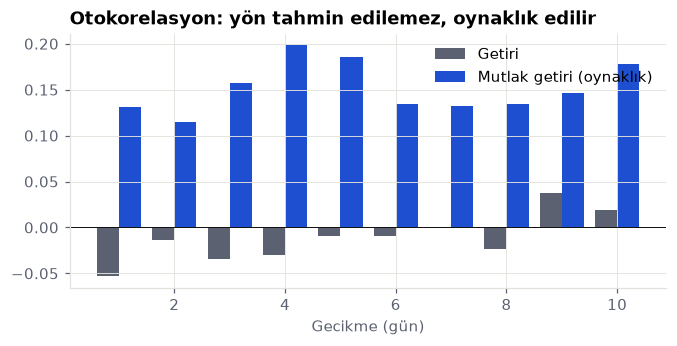

In [3]:
x = r['NDX'].dropna()
ac_ret = [x.autocorr(l) for l in range(1, 11)]
ac_abs = [x.abs().autocorr(l) for l in range(1, 11)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(np.arange(1, 11) - .2, ac_ret, .4, label='Getiri', color=charts.MUTED)
ax.bar(np.arange(1, 11) + .2, ac_abs, .4, label='Mutlak getiri (oynaklık)', color=charts.ACC)
ax.axhline(0, color='k', lw=.6); ax.set_xlabel('Gecikme (gün)'); ax.set_title('Otokorelasyon: yön tahmin edilemez, oynaklık edilir'); ax.legend(frameon=False); plt.show()

**Yorum:** Getirinin kendisinin otokorelasyonu sıfıra yakın (yarının yönü bugünden tahmin edilemez), ama mutlak getirininki belirgin pozitif: büyük hareketli günleri büyük hareketli günler izler. Risk yönetiminde oynaklığın son dönem değerinin kullanılmasının nedeni bu.

## 2.3 İlişkiler zamanla değişiyor mu?

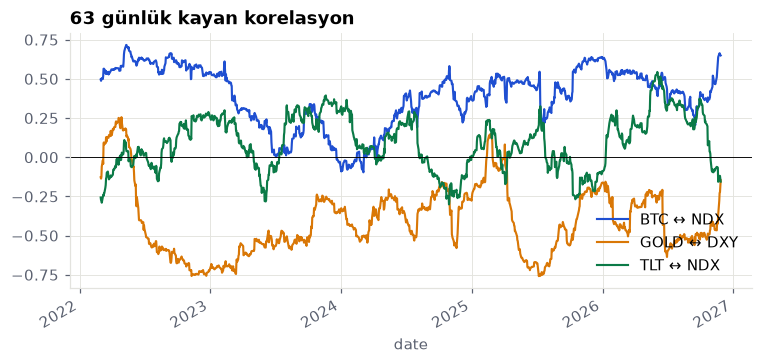

In [4]:
pairs = [('BTC', 'NDX'), ('GOLD', 'DXY'), ('TLT', 'NDX')]
fig, ax = plt.subplots(figsize=(8, 3.4))
for i, (a, b) in enumerate(pairs):
    st.rolling_corr(r, a, b, 63).plot(ax=ax, lw=1.4, color=charts.PALETTE[i], label=f'{a} ↔ {b}')
ax.axhline(0, color='k', lw=.6); ax.set_title('63 günlük kayan korelasyon'); ax.legend(frameon=False); plt.show()

**Hipotez testi:** Bitcoin ile Nasdaq 100 arasındaki korelasyon, son bir yılda önceki yıla göre değişti mi? İki bağımsız korelasyonun farkı için Fisher z dönüşümü kullanılır.

In [5]:
def fisher_test(r1, n1, r2, n2):
    z = (np.arctanh(r1) - np.arctanh(r2)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    return z, 2 * (1 - stats.norm.cdf(abs(z)))
a, b = r[['BTC', 'NDX']].dropna().iloc[-252:], r[['BTC', 'NDX']].dropna().iloc[-504:-252]
r1, r2 = a.corr().iloc[0, 1], b.corr().iloc[0, 1]
z, p = fisher_test(r1, len(a), r2, len(b))
print(f'Son 1 yıl: {r1:.2f}, önceki yıl: {r2:.2f}, z = {z:.2f}, p = {p:.3f}')
print('Fark istatistiksel olarak anlamlı.' if p < .05 else 'Fark anlamlı değil: ilişki iki yılda benzer.')

Son 1 yıl: 0.46, önceki yıl: 0.48, z = -0.27, p = 0.784
Fark anlamlı değil: ilişki iki yılda benzer.


## 2.4 Kötü günlerde çeşitlendirme
Korelasyonlar sakin günlerde düşük, panik günlerinde yüksek olabilir; yani çeşitlendirme tam ihtiyaç duyulduğunda çalışmayabilir. Nasdaq 100'ün en kötü %10'luk günlerinde korelasyonu, diğer günlerle karşılaştıralım.

In [6]:
bad = r['NDX'] <= r['NDX'].quantile(.10)
cols = ['SPX', 'GOLD', 'BTC', 'TLT', 'OIL', 'DXY']
cmp = pd.DataFrame({'kötü günler': r[bad][cols].corrwith(r[bad]['NDX']), 'diğer günler': r[~bad][cols].corrwith(r[~bad]['NDX'])})
cmp['fark'] = cmp['kötü günler'] - cmp['diğer günler']; cmp

,kötü günler,diğer günler,fark
code,,,
SPX,0.89,0.93,-0.04
GOLD,0.13,0.10,0.03
BTC,0.31,0.33,-0.02
TLT,-0.06,0.08,-0.15
OIL,0.10,-0.07,0.16
DXY,-0.00,-0.23,0.23


## 2.5 En büyük düşüşler (SQL)

In [7]:
db.query('drawdowns', con).head(15)

,code,name,cls,max_drawdown,trough_date,current_drawdown
0,MRNA,Moderna,hisse,-93.90,2025-11-20,-38.00
1,APP,AppLovin,hisse,-90.40,2022-12-27,-45.60
2,MSTR,Strategy,hisse,-83.60,2026-11-24,-82.80
3,SHOP,Shopify,hisse,-83.60,2022-10-11,-20.90
4,PYPL,PayPal Holdings,hisse,-80.20,2026-02-12,-69.70
5,CRWV,CoreWeave,hisse,-78.50,2026-11-20,-76.00
6,RKLB,Rocket Lab,hisse,-77.70,2024-04-15,-66.10
7,DASH,DoorDash,hisse,-76.50,2022-10-14,-40.40
8,NFLX,Netflix,hisse,-74.90,2022-05-11,-54.50
9,META,Meta Platforms,hisse,-74.30,2022-11-03,-20.10
